<a href="https://colab.research.google.com/github/palakkadyan007-a/Grade-Prediction-EDA/blob/main/Grade_Pridiction_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()


Saving archive.zip to archive.zip


In [ ]:
import pandas as pd

file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

df.head()

,student_id,academic_year,survey_date,age,gender,grade_level,school_type,residence_type,family_size,num_siblings,...,distance_to_school_km,scholarship_status,extra_tutoring,parental_involvement_score,study_hours_per_week,attendance_rate_pct,previous_year_grade_pct,final_grade_pct,grade_class,at_risk_flag
0,STU101529,2024-2025,2025-03-06,16,Male,12,Government,Rural,3,0,...,4.0,No Scholarship,0,4,15.0,76.8,61.7,59.4,D,0
1,STU107546,2022-2023,2025-05-02,15,Male,10,Government,Urban,3,1,...,0.7,No Scholarship,0,3,20.9,74.5,49.2,60.2,C,0
2,STU103737,2024-2025,2025-03-21,14,Male,9,Government,Urban,2,0,...,2.9,No Scholarship,0,4,20.9,94.9,56.9,58.4,D,0
3,STU108172,2023-2024,2025-03-30,13,Male,8,Government,Rural,6,4,...,7.0,No Scholarship,0,1,6.5,63.6,49.3,57.0,D,0
4,STU110633,2023-2024,2025-05-06,11,Female,6,Private-Unaided,Rural,5,3,...,9.1,No Scholarship,0,5,13.9,86.0,79.3,88.7,B,0


In [ ]:
# understanding the given dataset

print("Dataset shape:", df.shape)

df.head()

df.tail()

print("Number of rows:", df.shape[0])

print("Number of columns:", df.shape[1])

df.columns

df.info()

df.dtypes

df.describe()

numerical_columns = df.select_dtypes(include='number').columns

categorical_columns = df.select_dtypes(include='object').columns

print("Numerical Columns:")
print(list(numerical_columns))

print("\nCategorical Columns:")
print(list(categorical_columns))

Dataset shape: (12025, 29)
Number of rows: 12025
Number of columns: 29
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12025 entries, 0 to 12024
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  12025 non-null  object 
 1   academic_year               12025 non-null  object 
 2   survey_date                 12025 non-null  object 
 3   age                         12025 non-null  int64  
 4   gender                      12025 non-null  object 
 5   grade_level                 12025 non-null  int64  
 6   school_type                 12025 non-null  object 
 7   residence_type              12025 non-null  object 
 8   family_size                 12025 non-null  int64  
 9   num_siblings                12025 non-null  int64  
 10  single_parent_household     12025 non-null  int64  
 11  family_income_bracket       12025 non-null  object 
 12  annual_family_inc

In [ ]:
# cleaning the above data

df.isnull().sum()

for col in df.select_dtypes(include='number').columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include='object').columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

df.duplicated().sum()

df.isnull().sum().sum()

np.int64(0)

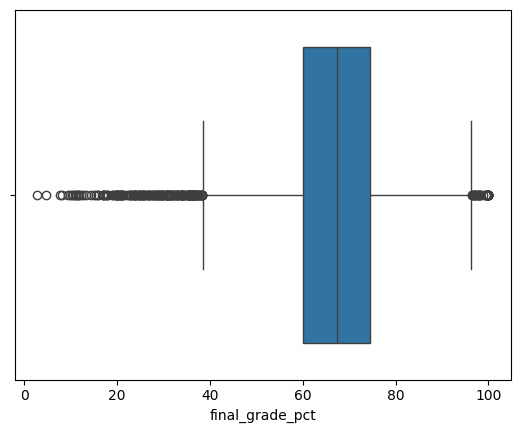

In [ ]:
# outlier detection

Q1 = df.select_dtypes(include='number').quantile(0.25)
Q3 = df.select_dtypes(include='number').quantile(0.75)

IQR = Q3 - Q1

outliers = ((df.select_dtypes(include='number') < (Q1 - 1.5 * IQR)) |
            (df.select_dtypes(include='number') > (Q3 + 1.5 * IQR)) )

outliers.sum()

import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df['final_grade_pct'])
plt.show()

In [ ]:
# identify ptterns

df.describe()

# 1. Students have an average final grade of approximately 66.94%.
# 2.Average final grades are higher than average previous-year grades.
# 3.Average attendance is approximately 85.85%.
# 4.Family income has a large difference between its mean and median, suggesting a right-skewed distribution.
# 5.The dataset includes students aged 10–18 and grade levels 6–12.

df['grade_class'].value_counts()

# Grade distribution helps us understand how students are performing across different academic categories.

,count
grade_class,
C,6147
D,2740
B,2686
F,218
A,209


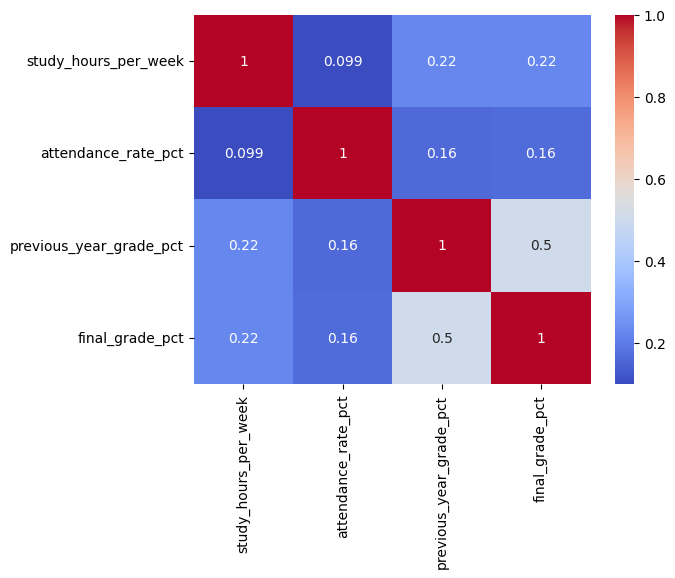

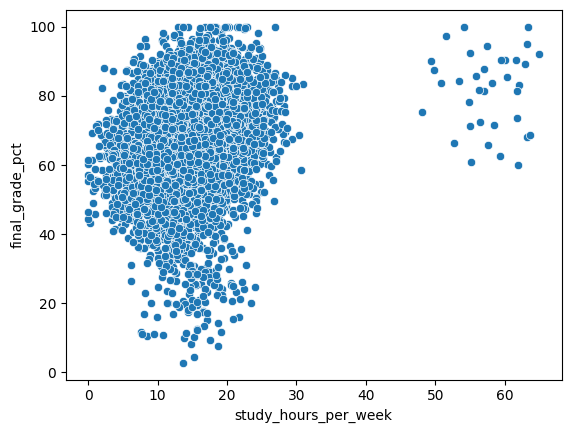

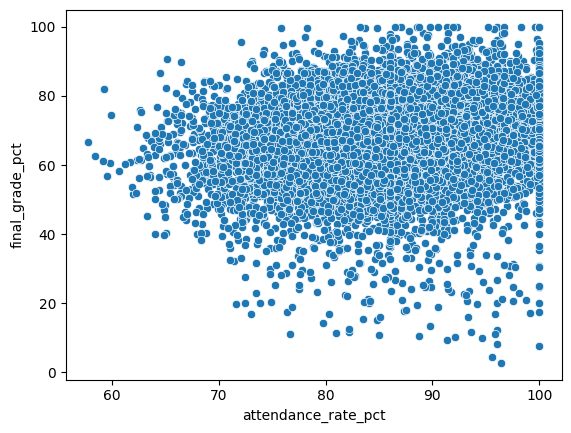

In [ ]:
# understanding relationships
cols = ['study_hours_per_week', 'attendance_rate_pct',
        'previous_year_grade_pct', 'final_grade_pct']

df[cols].corr()

sns.heatmap(df[cols].corr(), annot=True, cmap='coolwarm')
plt.show()

sns.scatterplot(data=df, x='study_hours_per_week', y='final_grade_pct')
plt.show()

sns.scatterplot(data=df, x='attendance_rate_pct', y='final_grade_pct')
plt.show()



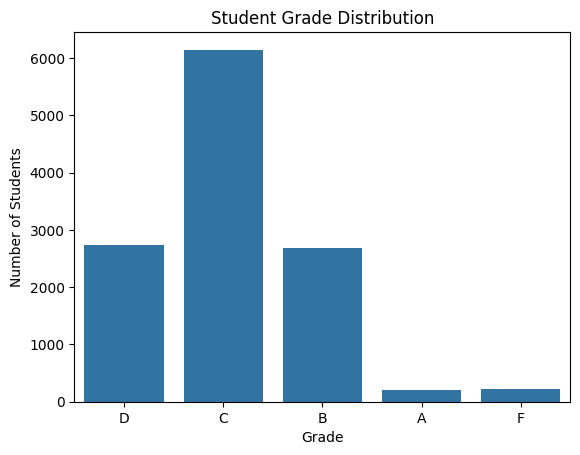

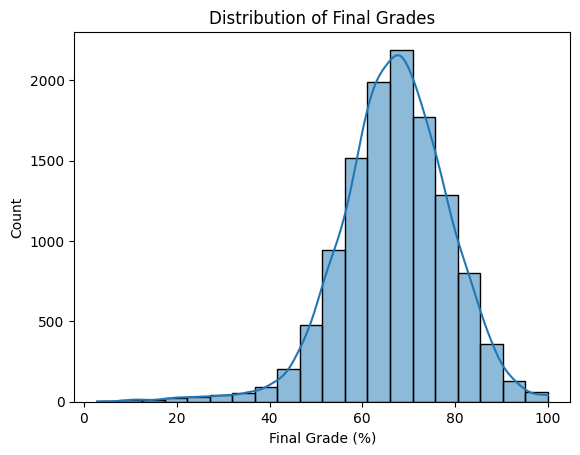

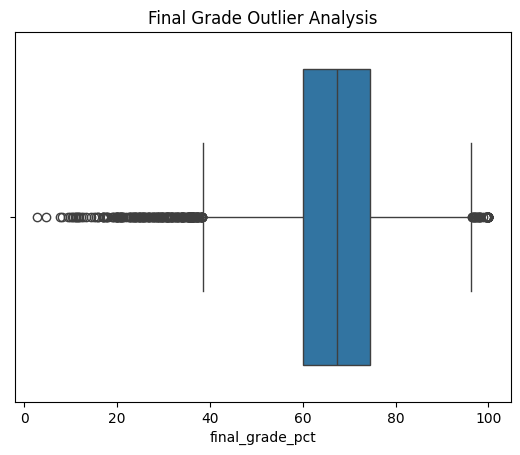

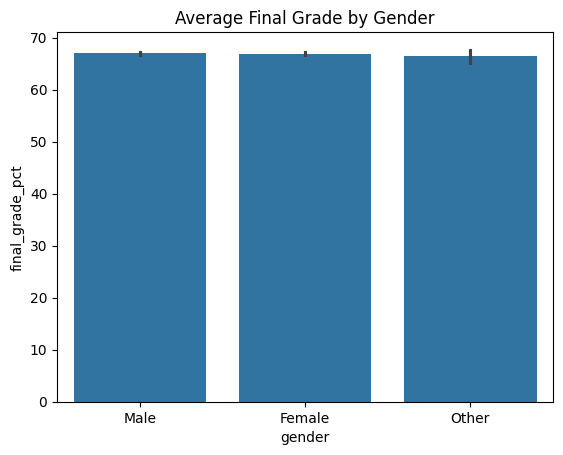

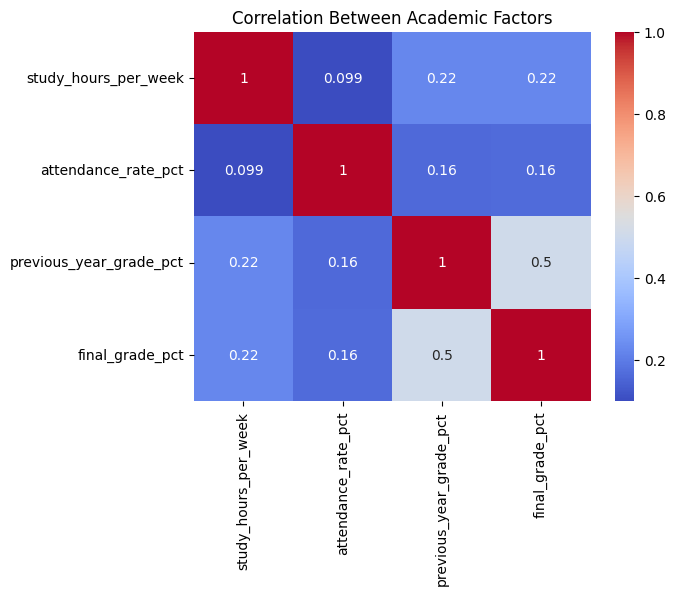

In [ ]:
# data visualization
sns.countplot(data=df, x='grade_class')
plt.title('Student Grade Distribution')
plt.xlabel('Grade')
plt.ylabel('Number of Students')
plt.show()

sns.histplot(df['final_grade_pct'], bins=20, kde=True)
plt.title('Distribution of Final Grades')
plt.xlabel('Final Grade (%)')
plt.show()

sns.boxplot(x=df['final_grade_pct'])
plt.title('Final Grade Outlier Analysis')
plt.show()

sns.barplot(data=df, x='gender', y='final_grade_pct')
plt.title('Average Final Grade by Gender')
plt.show()

sns.heatmap(df[cols].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Between Academic Factors')
plt.show()

In [ ]:
# prepare dataset for ml
X = df.drop(columns=['final_grade_pct', 'grade_class', 'at_risk_flag',
                     'student_id', 'survey_date'], errors='ignore')

y = df['final_grade_pct']

X = pd.get_dummies(X, drop_first=True, dtype=int)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train.shape, X_test.shape

((9600, 54), (2400, 54))